# Demo: Dự đoán giá nhà bằng Hồi quy tuyến tính

Mỗi căn nhà được mô tả bởi 3 đặc trưng:

| Ký hiệu | Đặc trưng | Cột dữ liệu | Đơn vị |
|---|---|---|---|
| $x_1$ | Diện tích | `dien_tich` | m² |
| $x_2$ | Số phòng ngủ | `so_phong_ngu` | phòng |
| $x_3$ | Khoảng cách tới trung tâm | `khoang_cach` | km |
| $y$ | Giá nhà | `gia` | triệu VND |

Mô hình: $\hat{y} = w_0 + w_1 x_1 + w_2 x_2 + w_3 x_3 = \bar{\mathbf{x}}^T \bar{\mathbf{w}}$

Dữ liệu mẫu gồm **10000 căn nhà** trong file `../data/gia_nha.csv` (sinh bởi `../data/tao_du_lieu.ipynb`).

## 1. Đọc và khám phá dữ liệu

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('../data/gia_nha.csv')
print('Kích thước dữ liệu:', df.shape)

# Tên tiếng Việt của các cột, chỉ dùng khi hiển thị bảng
ten_cot = {
    'dien_tich': 'Diện tích (m²)',
    'so_phong_ngu': 'Số phòng ngủ',
    'khoang_cach': 'Khoảng cách (km)',
    'gia': 'Giá (triệu VND)',
}
df.head().rename(columns=ten_cot)

Kích thước dữ liệu: (10000, 4)


,Diện tích (m²),Số phòng ngủ,Khoảng cách (km),Giá (triệu VND)
0,93.7,1,7.0,3477.0
1,191.6,4,3.7,6220.0
2,154.4,4,7.7,5514.0
3,131.8,2,6.9,4771.0
4,56.5,2,16.1,957.0


In [2]:
# Thống kê mô tả của từng cột
ten_thong_ke = {
    'count': 'Số lượng', 'mean': 'Trung bình', 'std': 'Độ lệch chuẩn',
    'min': 'Nhỏ nhất', '25%': 'Phân vị 25%', '50%': 'Trung vị',
    '75%': 'Phân vị 75%', 'max': 'Lớn nhất',
}
df.describe().round(2).rename(index=ten_thong_ke, columns=ten_cot)

,Diện tích (m²),Số phòng ngủ,Khoảng cách (km),Giá (triệu VND)
Số lượng,10000.00,10000.00,10000.00,10000.00
Trung bình,114.01,2.90,12.67,3593.07
Độ lệch chuẩn,48.90,1.36,7.03,1712.70
Nhỏ nhất,30.00,1.00,0.50,300.00
Phân vị 25%,71.90,2.00,6.60,2164.75
Trung vị,113.70,3.00,12.70,3575.00
Phân vị 75%,155.83,4.00,18.70,4991.25
Lớn nhất,200.00,6.00,25.00,7722.00


**Giải thích:**

- Có **1000 căn nhà**, không thiếu dữ liệu (cột *Số lượng* đều bằng 1000).
- Diện tích từ khoảng 31 đến 200 m², trung bình khoảng 113 m².
- Số phòng ngủ từ 1 đến 6; khoảng cách tới trung tâm từ 0.5 đến 24.9 km.
- Giá nhà từ 300 đến khoảng 7500 triệu, trung bình khoảng 3589 triệu.
- Các đặc trưng có **thang đo rất khác nhau** (diện tích hàng trăm, số phòng chỉ vài đơn vị), điều này ảnh hưởng đến Gradient Descent ở mục 5.

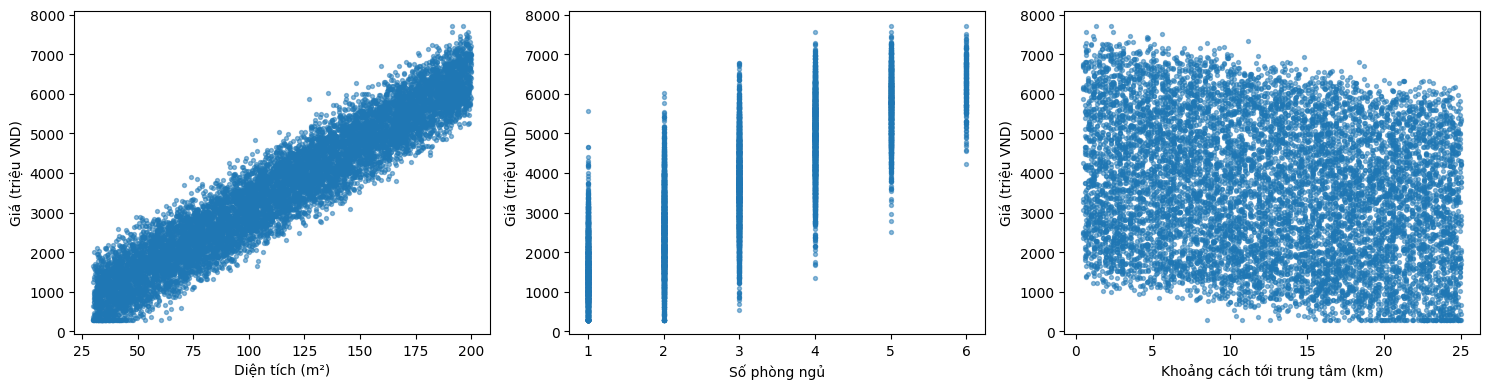

In [3]:
# Quan hệ giữa từng đặc trưng và giá nhà
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
cot = ['dien_tich', 'so_phong_ngu', 'khoang_cach']
ten = ['Diện tích (m²)', 'Số phòng ngủ', 'Khoảng cách tới trung tâm (km)']
for ax, c, t in zip(axes, cot, ten):
    ax.scatter(df[c], df['gia'], s=8, alpha=0.5)
    ax.set_xlabel(t)
    ax.set_ylabel('Giá (triệu VND)')
plt.tight_layout()
plt.show()

**Giải thích:** mỗi điểm là một căn nhà.

- Đồ thị 1: các điểm đi lên rõ rệt, nhà càng rộng càng đắt.
- Đồ thị 2: số phòng ngủ là số nguyên nên điểm xếp thành cột; nhiều phòng thì giá cao hơn.
- Đồ thị 3: các điểm hơi đi xuống, càng xa trung tâm giá càng giảm nhưng mức ảnh hưởng yếu hơn.

In [4]:
# Hệ số tương quan giữa các biến
df.corr().round(3).rename(index=ten_cot, columns=ten_cot)

,Diện tích (m²),Số phòng ngủ,Khoảng cách (km),Giá (triệu VND)
Diện tích (m²),1.000,0.851,0.006,0.952
Số phòng ngủ,0.851,1.000,0.018,0.839
Khoảng cách (km),0.006,0.018,1.000,-0.237
Giá (triệu VND),0.952,0.839,-0.237,1.000


**Nhận xét:** giá nhà **tăng** theo diện tích và số phòng ngủ, **giảm** khi xa trung tâm.
Diện tích và số phòng ngủ tương quan khá mạnh với nhau (nhà rộng thường nhiều phòng hơn).

## 2. Chia tập huấn luyện / kiểm tra 


In [5]:
from sklearn.model_selection import train_test_split

X = df[['dien_tich', 'so_phong_ngu', 'khoang_cach']].values   # mỗi hàng là một mẫu
y = df['gia'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print('Tập huấn luyện:', X_train.shape, ' Tập kiểm tra:', X_test.shape)

Tập huấn luyện: (7000, 3)  Tập kiểm tra: (3000, 3)


**Giải thích:**

- `X` có 3 cột (3 đặc trưng), `y` là giá nhà.
- `test_size=0.3`: 30% dữ liệu (3000 căn) để **kiểm tra**, 70% (7000 căn) để **huấn luyện**. Mô hình không được thấy tập kiểm tra khi học, nhờ đó ta đánh giá được khả năng dự đoán trên dữ liệu mới.
- `random_state=42`: cố định cách chia ngẫu nhiên để mỗi lần chạy đều cho cùng kết quả.

## 3. Nghiệm theo công thức (Normal Equation)

$$\bar{\mathbf{w}} = (\bar{\mathbf{X}}^T \bar{\mathbf{X}})^{\dagger} \bar{\mathbf{X}}^T \mathbf{y}$$

trong đó $\bar{\mathbf{X}}$ là $\mathbf{X}$ được thêm cột toàn số 1 ở đầu.

In [6]:
# Tạo ma trận Xbar (thêm cột 1 vào trước ma trận X)
one = np.ones((X_train.shape[0], 1))
Xbar = np.concatenate((one, X_train), axis=1)

# w = (Xbar^T Xbar)^+ Xbar^T y
A = Xbar.T @ Xbar
b = Xbar.T @ y_train
w = np.linalg.pinv(A) @ b

print('w0 (hệ số chệch)   = %.4f' % w[0])
print('w1 (diện tích)     = %.4f' % w[1])
print('w2 (số phòng ngủ)  = %.4f' % w[2])
print('w3 (khoảng cách)   = %.4f' % w[3])

w0 (hệ số chệch)   = 503.7191
w1 (diện tích)     = 30.0532
w2 (số phòng ngủ)  = 143.0904
w3 (khoảng cách)   = -59.5443


**Ý nghĩa các hệ số** (dữ liệu được sinh với $w_0=500,\ w_1=30,\ w_2=150,\ w_3=-60$):
- $w_1$: mỗi m² tăng thêm làm giá tăng khoảng $w_1$ triệu.
- $w_2$: mỗi phòng ngủ thêm làm giá tăng khoảng $w_2$ triệu.
- $w_3 < 0$: mỗi km xa trung tâm hơn làm giá giảm khoảng $|w_3|$ triệu.

## 4. Sử dụng thư viện scikit-learn

In [7]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print('Kết quả từ scikit-learn:')
print('  w0 =', round(model.intercept_, 4))
print('  w1, w2, w3 =', np.round(model.coef_, 4))
print('Kết quả tính thủ công:')
print('  w0 =', round(w[0], 4))
print('  w1, w2, w3 =', np.round(w[1:], 4))

Kết quả từ scikit-learn:
  w0 = 503.7191
  w1, w2, w3 = [ 30.0532 143.0904 -59.5443]
Kết quả tính thủ công:
  w0 = 503.7191
  w1, w2, w3 = [ 30.0532 143.0904 -59.5443]


**Giải thích:** `model.intercept_` là $w_0$, `model.coef_` là $[w_1, w_2, w_3]$.
Kết quả của scikit-learn **trùng khớp** với nghiệm tính thủ công ở mục 3, vì `LinearRegression` cũng giải bài toán bình phương tối thiểu.

## 5. Giải bằng Gradient Descent

$$\mathbf{w} \leftarrow \mathbf{w} - \frac{\eta}{N} \bar{\mathbf{X}}^T (\bar{\mathbf{X}}\mathbf{w} - \mathbf{y})$$

Các đặc trưng có thang đo rất khác nhau (diện tích ~100, số phòng ~3), nên cần **chuẩn hóa** (standardization) để Gradient Descent hội tụ nhanh:
$x' = \dfrac{x - \mu}{\sigma}$. Sau khi huấn luyện, ta đổi trọng số về thang đo gốc để so sánh.

In [ ]:
mu = X_train.mean(axis=0)
sigma = X_train.std(axis=0)
Xs = (X_train - mu) / sigma
Xs_bar = np.concatenate((np.ones((Xs.shape[0], 1)), Xs), axis=1)

def loss(w, Xb, y):
    e = y - Xb @ w
    return (e @ e) / (2 * len(y))

eta = 0.1
w_gd = np.zeros(Xs_bar.shape[1])
lich_su = []
for it in range(500):
    grad = Xs_bar.T @ (Xs_bar @ w_gd - y_train) / len(y_train)
    w_gd = w_gd - eta * grad
    lich_su.append(loss(w_gd, Xs_bar, y_train))

# Đổi trọng số về thang đo gốc
w_goc = w_gd[1:] / sigma
w0_goc = w_gd[0] - np.sum(w_gd[1:] * mu / sigma)
print('Gradient Descent: w0 = %.4f, w1, w2, w3 =' % w0_goc, np.round(w_goc, 4))
print('Normal Equation : w0 = %.4f, w1, w2, w3 =' % w[0], np.round(w[1:], 4))

plt.plot(lich_su)
plt.xlabel('Vòng lặp')
plt.ylabel('Hàm mất mát L(w)')
plt.yscale('log')
plt.title('Quá trình hội tụ của Gradient Descent')
plt.show()

**Giải thích:**

- Mỗi vòng lặp, trọng số được cập nhật ngược hướng gradient với bước học $\eta = 0.1$.
- Đồ thị (trục tung thang log) cho thấy hàm mất mát **giảm nhanh** rồi đi ngang, tức thuật toán đã hội tụ.
- Sau 500 vòng lặp, nghiệm của Gradient Descent rất gần nghiệm của Normal Equation; chênh lệch nhỏ còn lại sẽ giảm nếu chạy thêm vòng lặp.

## 6. Đánh giá mô hình trên tập kiểm tra

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)

print('MAE  = %.2f triệu' % mean_absolute_error(y_test, y_pred))
print('MSE  = %.2f' % mse)
print('RMSE = %.2f triệu' % np.sqrt(mse))
print('R^2  = %.4f' % r2_score(y_test, y_pred))

- **MAE ≈ 234 triệu:** trung bình mỗi dự đoán lệch khoảng 234 triệu, tức khoảng 6.5% so với giá trung bình (~3589 triệu).
- **RMSE ≈ 284 triệu:** lớn hơn MAE một chút vì RMSE phạt nặng các sai số lớn.
- **MSE** có đơn vị triệu², khó diễn giải trực tiếp nên thường dùng RMSE.
- **$R^2$ ≈ 0.972:** mô hình giải thích được khoảng 97% sự biến thiên của giá nhà.

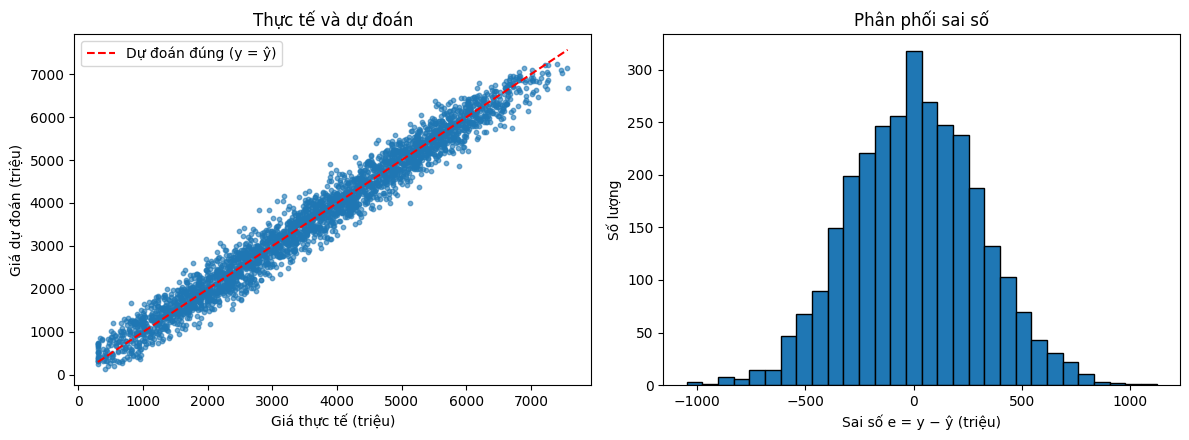

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Giá thực tế và giá dự đoán
axes[0].scatter(y_test, y_pred, s=10, alpha=0.6)
lim = [y_test.min(), y_test.max()]
axes[0].plot(lim, lim, 'r--', label='Dự đoán đúng (y = ŷ)')
axes[0].set_xlabel('Giá thực tế (triệu)')
axes[0].set_ylabel('Giá dự đoán (triệu)')
axes[0].set_title('Thực tế và dự đoán')
axes[0].legend()

# Phân phối sai số
axes[1].hist(y_test - y_pred, bins=30, edgecolor='k')
axes[1].set_xlabel('Sai số e = y − ŷ (triệu)')
axes[1].set_ylabel('Số lượng')
axes[1].set_title('Phân phối sai số')
plt.tight_layout()
plt.show()

**Giải thích:**

- Hình trái: các điểm nằm sát đường đỏ $y = \hat{y}$, tức giá dự đoán gần với giá thực tế.
- Hình phải: sai số tập trung quanh 0, trải khá đều về hai phía, cho thấy mô hình không dự đoán lệch hẳn về một phía; phần sai số còn lại chủ yếu là nhiễu ngẫu nhiên.

## 7. Dự đoán giá cho căn nhà mới

In [11]:
nha_moi = pd.DataFrame({
    'dien_tich':    [60, 100, 150],
    'so_phong_ngu': [2, 3, 4],
    'khoang_cach':  [3, 10, 20],
})
nha_moi['gia'] = np.round(model.predict(nha_moi.values), 1)
nha_moi.rename(columns=ten_cot)

,Diện tích (m²),Số phòng ngủ,Khoảng cách (km),Giá (triệu VND)
0,60,2,3,2414.5
1,100,3,10,3342.9
2,150,4,20,4393.2


**Giải thích:** ba căn nhà mới có diện tích, số phòng và khoảng cách khác nhau.
Căn 150 m², 4 phòng có giá dự đoán cao nhất dù ở xa trung tâm (20 km), vì diện tích là yếu tố ảnh hưởng mạnh nhất tới giá.

## 8. Hồi quy Ridge và Lasso

Diện tích và số phòng ngủ tương quan mạnh (đa cộng tuyến). Ta so sánh hệ số của 3 mô hình.

In [ ]:
from sklearn.linear_model import Ridge, Lasso

ridge = Ridge(alpha=10.0).fit(X_train, y_train)
lasso = Lasso(alpha=10.0).fit(X_train, y_train)

ket_qua = pd.DataFrame({
    'Tuyến tính': np.r_[model.intercept_, model.coef_],
    'Ridge':  np.r_[ridge.intercept_, ridge.coef_],
    'Lasso':  np.r_[lasso.intercept_, lasso.coef_],
}, index=['w0', 'w1 (diện tích)', 'w2 (số phòng)', 'w3 (khoảng cách)']).round(3)
print(ket_qua)

for ten, m in [('Tuyến tính', model), ('Ridge', ridge), ('Lasso', lasso)]:
    p = m.predict(X_test)
    print('%-10s: RMSE = %.2f, R^2 = %.4f' % (ten, np.sqrt(mean_squared_error(y_test, p)), r2_score(y_test, p)))

**Giải thích:**

- Ridge và Lasso **thu nhỏ** hệ số, rõ nhất ở $w_2$ (số phòng): 175.4 → 171.4 (Ridge) → 157.0 (Lasso), gần hơn với giá trị thật 150 dùng để sinh dữ liệu.
- Lý do: diện tích và số phòng tương quan mạnh, nên mô hình tuyến tính thường khó tách bạch ảnh hưởng của từng biến; điều chuẩn giúp hệ số ổn định hơn.
- RMSE và $R^2$ của ba mô hình gần như bằng nhau: điều chuẩn không làm giảm chất lượng dự đoán.

In [ ]:
# Ảnh hưởng của lambda (alpha) lên hệ số Lasso - trên dữ liệu đã chuẩn hóa
from sklearn.preprocessing import StandardScaler
Xs_train = StandardScaler().fit_transform(X_train)

alphas = np.logspace(0, 3.5, 50)
coefs = np.array([Lasso(alpha=a).fit(Xs_train, y_train).coef_ for a in alphas])

for j, t in enumerate(['diện tích', 'số phòng ngủ', 'khoảng cách']):
    plt.plot(alphas, coefs[:, j], label=t)
plt.xscale('log')
plt.xlabel('alpha (λ)')
plt.ylabel('Hệ số (dữ liệu chuẩn hóa)')
plt.title('Lasso: hệ số bị đưa dần về 0 khi λ tăng')
plt.axhline(0, color='k', lw=0.5)
plt.legend()
plt.show()

**Giải thích:** dữ liệu được chuẩn hóa để so sánh công bằng hệ số giữa các đặc trưng.

- Khi $\lambda$ nhỏ, hệ số gần với hồi quy tuyến tính thông thường.
- Khi $\lambda$ tăng (khoảng 400–500), hệ số của **số phòng ngủ** và **khoảng cách** về đúng 0 trước: Lasso loại bỏ các đặc trưng kém quan trọng.
- **Diện tích** là đặc trưng quan trọng nhất nên bị đưa về 0 sau cùng (khi $\lambda \approx 2000$).

## 9. Kết luận

- Hồi quy tuyến tính khôi phục khá sát các hệ số thật dùng để sinh dữ liệu.
- Normal Equation, scikit-learn và Gradient Descent cho **cùng một nghiệm**.
- $R^2$ gần 1 cho thấy mô hình tuyến tính giải thích tốt phần lớn biến thiên của giá nhà; phần sai số còn lại là do **nhiễu** trong dữ liệu.
- Khi $\lambda$ tăng, Lasso đưa dần các hệ số kém quan trọng về **0** (lựa chọn đặc trưng).